# End-to-end run: download → transform → predict → simulate → latest trades

This notebook runs the **whole automated workflow** with the project modules in `trading/`
(the same code that `python main.py run` and the cron job use).

* `MODE = "fetch"` downloads only the missing days from the APIs (incremental) and rebuilds features.
* `MODE = "local"` uses the data already stored in `data/raw` — no network needed.

The models and the chosen strategy come from the research run (`python main.py research`,
see `01_research.ipynb`). Set `RETRAIN = True` to redo that research here (~30+ min).

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT); sys.path.insert(0, str(PROJECT))

import json
import pandas as pd
import matplotlib.pyplot as plt
from trading import config as C, pipeline as P

MODE = "local"      # "fetch" | "local"
RETRAIN = False

## 1. Get the data (5 providers: yfinance, FRED, CBOE, Wikipedia + yfinance sectors)

In [2]:
repo = P.get_data(MODE)
print(f"stocks: {len(repo.stocks_df):,} rows, {repo.stocks_df.Ticker.nunique()} tickers, "
      f"{repo.stocks_df.Date.min().date()} .. {repo.stocks_df.Date.max().date()}")
print("market symbols:", sorted(repo.market_df.Ticker.unique()))
print("FRED series:", [c for c in repo.macro_df.columns if c != "Date"])
print("CBOE series:", [c for c in repo.cboe_df.columns if c != "Date"])

stocks: 1,137,083 rows, 190 tickers, 1998-11-27 .. 2026-11-13
market symbols: ['BTC-USD', 'CL=F', 'DX-Y.NYB', 'GC=F', 'SPY', '^DJI', '^GSPC', '^IXIC', '^RUT', '^VIX']
FRED series: ['GDPPOT', 'CPILFESL', 'FEDFUNDS', 'UNRATE', 'DGS3MO', 'DGS1', 'DGS5', 'DGS10', 'BAA10Y']
CBOE series: ['vix9d', 'vix3m', 'vvix', 'skew']


## 2. Transform into one dataframe with feature sets

In [3]:
t = P.build_dataset(repo)
print(t.df.shape)
print({k: len(v) for k, v in t.feature_sets.items()})

features per ticker:   0%|          | 0/190 [00:00<?, ?it/s]

features per ticker:   1%|          | 2/190 [00:00<00:09, 19.81it/s]

features per ticker:   3%|▎         | 6/190 [00:00<00:06, 28.65it/s]

features per ticker:   5%|▍         | 9/190 [00:00<00:06, 28.96it/s]

features per ticker:   6%|▋         | 12/190 [00:00<00:06, 28.86it/s]

features per ticker:   8%|▊         | 16/190 [00:00<00:05, 30.49it/s]

... (40 outputs left out)

features per ticker:  97%|█████████▋| 185/190 [00:05<00:00, 35.15it/s]

features per ticker:  99%|█████████▉| 189/190 [00:05<00:00, 33.71it/s]

features per ticker: 100%|██████████| 190/190 [00:05<00:00, 33.59it/s]

dataset (1101330, 320) saved to /Users/donnabrown/Desktop/stock-market-analytics/project/data/processed
(1101330, 320)
{'TO_PREDICT': 7, 'CATEGORICAL': 4, 'NUMERIC': 300, 'PATTERNS': 61, 'NEW_FEATURES': 56}


## 3. Predict with the saved models (or retrain)

In [4]:
if RETRAIN:
    preds = P.research(t)
else:
    preds = P.score_with_saved_models(t)
preds.split.value_counts()

features: 300 numeric + 28 dummies = 328
rows per split: {'train': 732790, 'test': 204539, 'validation': 158294, 'embargo': 3817, 'live': 1890}


features: 300 numeric + 28 dummies = 328
rows per split: {'train': 732790, 'test': 204539, 'validation': 158294, 'embargo': 3817, 'live': 1890}


split
test          204539
validation    158294
live            1890
Name: count, dtype: int64

## 4. Simulate the strategies on the test period

In [5]:
strategy = json.loads(P.BEST_STRATEGY_FILE.read_text())
print("strategy chosen on validation:", strategy)
from trading.simulate import Strategy
s_best = Strategy(**strategy)
named = [Strategy("S1_top5_equal", strategy["score"], top_k=5), s_best]
res, curves, trades = P.test_report(preds, repo.market_df, named)
res[["name", "CAGR", "sharpe", "max_drawdown", "n_trades", "win_rate"]]

strategy chosen on validation: {'name': 'S5_best_on_validation', 'score': 'proba_rf_rel', 'top_k': 5, 'threshold': 0.0, 'stop_loss': 0.1, 'regime_filter': False, 'sizing': 'equal'}


,name,CAGR,sharpe,max_drawdown,n_trades,win_rate
0,S1_top5_equal,0.219166,1.293848,-0.178926,5390.0,0.560482
1,S5_best_on_validation,0.198785,1.313097,-0.172769,5391.0,0.557040
2,SPY_buy_and_hold,0.186370,1.149343,-0.187552,NaN,NaN
3,equal_weight_universe,0.298865,1.725457,-0.179417,NaN,NaN


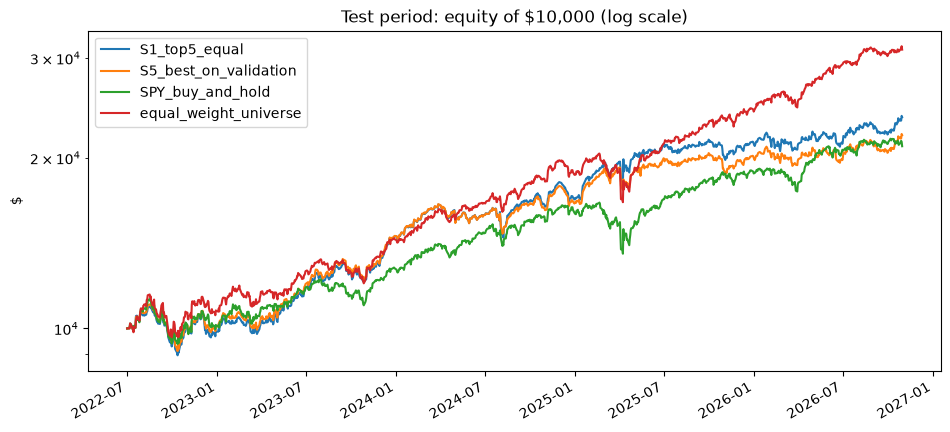

In [6]:
ax = curves.plot(figsize=(11, 5), logy=True, title="Test period: equity of $10,000 (log scale)")
ax.set_ylabel("$"); plt.show()

## 5. Latest trades (what to buy at the last available close)

In [7]:
picks = P.latest_trades(preds, strategy)
print("last date:", preds.Date.max().date(), "| market regime OK:", picks.attrs["regime_ok"])
picks

last date: 2026-11-13 | market regime OK: True


,Date,Ticker,sector,Close,proba_rf_rel,rank,stop_price,planned_exit
0,2026-11-13,ET,Energy,19.400000,0.547055,1,17.459999,close of the 10th trading day after 2026-11-13
1,2026-11-13,CTAS,Industrials,226.240005,0.545403,2,203.615997,close of the 10th trading day after 2026-11-13
2,2026-11-13,WELL,Real Estate,244.460007,0.544658,3,220.014008,close of the 10th trading day after 2026-11-13
3,2026-11-13,SCCO,Materials,164.080002,0.537487,4,147.671997,close of the 10th trading day after 2026-11-13
4,2026-11-13,CRM,Information Technology,217.839996,0.536549,5,196.055984,close of the 10th trading day after 2026-11-13


In [8]:
print("last 10 closed trades of the best strategy in the test period:")
trades[strategy["name"]].tail(10)

last 10 closed trades of the best strategy in the test period:


,ticker,entry_date,entry_px,proba,alloc,exit_date,exit_px,reason,return
5381,BRK-B,2026-10-15,525.679993,0.548211,414.529268,2026-10-29,541.960022,time,0.028909
5382,COST,2026-10-15,976.566650,0.538811,414.529268,2026-10-29,994.609985,time,0.016440
5383,PG,2026-10-15,156.046967,0.531929,414.529268,2026-10-29,160.589996,time,0.027056
5384,ET,2026-10-15,19.524666,0.531641,414.529268,2026-10-29,20.506792,time,0.048202
5385,ECL,2026-10-15,290.809998,0.531211,414.529268,2026-10-29,300.859985,time,0.032490
5386,RSG,2026-10-16,231.539993,0.535586,427.595914,2026-10-30,244.039993,time,0.051879
5387,COST,2026-10-16,987.650269,0.534783,427.595914,2026-10-30,1012.280029,time,0.022889
5388,CSX,2026-10-16,48.680000,0.533419,427.595914,2026-10-30,51.990002,time,0.065860
5389,BX,2026-10-16,105.602463,0.531536,427.595914,2026-10-30,117.389999,time,0.109400
5390,BRK-B,2026-10-16,532.020020,0.530653,427.595914,2026-10-30,542.489990,time,0.017641
